In [6]:
# 导入 Gymnasium 环境库（新版 gym，替代旧版 gym）
import gymnasium as gym
# 导入 PyTorch，用于张量运算和噪声生成
import torch
# 导入 Matplotlib，用于绘制奖励曲线
import matplotlib.pyplot as plt

# 创建 CartPole-v1 环境（v1 最大步数 500，v0 是 200）
env = gym.make('CartPole-v1')

# 状态维度：4（小车位置、小车速度、杆子角度、杆子角速度）
n_state = env.observation_space.shape[0]
# 动作数量：2（0=向左推，1=向右推）
n_action = env.action_space.n


def run_episode(env, weight):
    """
    用给定的权重矩阵跑完一个完整的 episode。

    策略：state(4,) × weight(4,2) → 2 维得分，取 argmax 作为动作。
    这是一个线性策略，没有隐藏层、没有激活函数。

    参数:
        env: Gymnasium 环境
        weight: 形状为 (n_state, n_action) 的权重矩阵

    返回:
        该 episode 的累计奖励（即存活步数）
    """
    # 重置环境，获取初始状态（新版 gymnasium 返回两个值）
    state, info = env.reset()
    total_reward = 0
    terminated = False  # 任务是否自然结束（杆倒了 / 车出界）
    truncated = False   # 是否因达到最大步数而截断

    while not (terminated or truncated):
        # 将 numpy 数组转为 PyTorch 浮点张量
        state = torch.from_numpy(state).float()
        # 线性映射 + argmax 选动作
        action = torch.argmax(torch.matmul(state, weight))
        # 执行动作（新版返回 5 个值）
        state, reward, terminated, truncated, info = env.step(action.item())
        total_reward += reward

    return total_reward

In [7]:
# ==================== 第一部分：基础噪声搜索 ====================

n_episode = 1000

# 初始随机权重作为搜索起点
best_weight = torch.rand(n_state, n_action)
best_total_reward = 0  # 历史最佳奖励
total_rewards = []     # 记录每轮奖励

# 噪声幅度：在最优权重基础上加一个小扰动来探索
noise_scale = 0.01

for episode in range(n_episode):
    # 在最优权重上叠加均匀分布的随机噪声
    weight = best_weight + noise_scale * torch.rand(n_state, n_action)
    total_reward = run_episode(env, weight)

    # 如果新权重表现不差于当前最优，就接受它（贪心更新）
    if total_reward >= best_total_reward:
        best_total_reward = total_reward
        best_weight = weight

    total_rewards.append(total_reward)
    print(f'Episode {episode + 1}: {total_reward}')

print(
    f'Average total reward over {n_episode} episode: '
    f'{sum(total_rewards) / n_episode:.2f}'
)


Episode 1: 10.0
Episode 2: 10.0
Episode 3: 10.0
Episode 4: 9.0
Episode 5: 10.0
Episode 6: 10.0
Episode 7: 10.0
Episode 8: 10.0
Episode 9: 9.0
Episode 10: 10.0
Episode 11: 9.0
Episode 12: 10.0
Episode 13: 10.0
Episode 14: 10.0
Episode 15: 9.0
Episode 16: 9.0
Episode 17: 10.0
Episode 18: 10.0
Episode 19: 9.0
Episode 20: 11.0
Episode 21: 9.0
Episode 22: 9.0
Episode 23: 10.0
Episode 24: 10.0
Episode 25: 9.0
Episode 26: 9.0
Episode 27: 10.0
Episode 28: 9.0
Episode 29: 10.0
Episode 30: 9.0
Episode 31: 10.0
Episode 32: 10.0
Episode 33: 10.0
Episode 34: 9.0
Episode 35: 9.0
Episode 36: 9.0
Episode 37: 10.0
Episode 38: 10.0
Episode 39: 10.0
Episode 40: 9.0
Episode 41: 10.0
Episode 42: 10.0
Episode 43: 10.0
Episode 44: 9.0
Episode 45: 10.0
Episode 46: 10.0
Episode 47: 10.0
Episode 48: 10.0
Episode 49: 9.0
Episode 50: 9.0
Episode 51: 10.0
Episode 52: 11.0
Episode 53: 9.0
Episode 54: 9.0
Episode 55: 9.0
Episode 56: 11.0
Episode 57: 10.0
Episode 58: 11.0
Episode 59: 10.0
Episode 60: 8.0
Episode 61: 

Episode 1: 134.0
Episode 2: 147.0
Episode 3: 98.0
Episode 4: 99.0
Episode 5: 125.0
Episode 6: 173.0
Episode 7: 172.0
Episode 8: 176.0
Episode 9: 123.0
Episode 10: 155.0
Episode 11: 142.0
Episode 12: 109.0
Episode 13: 57.0
Episode 14: 159.0
Episode 15: 306.0
Episode 16: 138.0
Episode 17: 47.0
Episode 18: 141.0
Episode 19: 113.0
Episode 20: 99.0
Episode 21: 10.0
Episode 22: 114.0
Episode 23: 175.0
Episode 24: 9.0
Episode 25: 235.0
Episode 26: 9.0
Episode 27: 10.0
Episode 28: 98.0
Episode 29: 110.0
Episode 30: 109.0
Episode 31: 9.0
Episode 32: 9.0
Episode 33: 8.0
Episode 34: 239.0
Episode 35: 487.0
Episode 36: 463.0
Episode 37: 89.0
Episode 38: 10.0
Episode 39: 10.0
Episode 40: 188.0
Episode 41: 67.0
Episode 42: 151.0
Episode 43: 122.0
Episode 44: 161.0
Episode 45: 196.0
Episode 46: 135.0
Episode 47: 418.0
Episode 48: 80.0
Episode 49: 135.0
Episode 50: 364.0
Episode 51: 90.0
Episode 52: 188.0
Episode 53: 245.0
Episode 54: 167.0
Episode 55: 56.0
Episode 56: 160.0
Episode 57: 162.0
Episode 

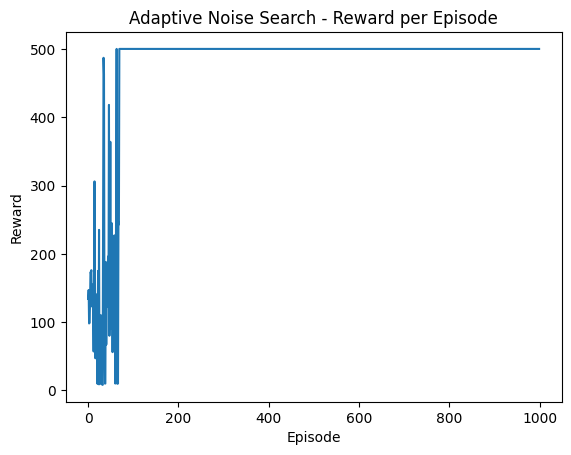

In [8]:
# ==================== 第二部分：自适应噪声搜索 ====================

# 重新初始化，避免沿用上一轮的结果
best_weight = torch.rand(n_state, n_action)
noise_scale = 0.01

best_total_reward = 0
total_rewards = []

for episode in range(n_episode):
    # 在最优权重上加噪声探索
    weight = best_weight + noise_scale * torch.rand(n_state, n_action)
    total_reward = run_episode(env, weight)

    if total_reward >= best_total_reward:
        # 找到更优权重：接受，并缩小噪声（局部精细搜索）
        best_total_reward = total_reward
        best_weight = weight
        noise_scale = max(noise_scale / 2, 1e-4)  # 最小不低于 1e-4
    else:
        # 没找到更优：放大噪声（扩大搜索范围，跳出局部最优）
        noise_scale = min(noise_scale * 2, 2)     # 最大不超过 2

    print(f'Episode {episode + 1}: {total_reward}')
    total_rewards.append(total_reward)

print(
    f'Average total reward over {n_episode} episode: '
    f'{sum(total_rewards) / n_episode:.2f}'
)

# 绘制奖励曲线
plt.plot(total_rewards)
plt.xlabel('Episode')
plt.ylabel('Reward')
plt.title('Adaptive Noise Search - Reward per Episode')
plt.show()


In [9]:
# ==================== 第三部分：用最优权重评估 ====================

n_episode_eval = 100
total_rewards_eval = []

for episode in range(n_episode_eval):
    # 用第二部分找到的最优权重跑评估
    total_reward = run_episode(env, best_weight)
    print(f'Episode {episode + 1}: {total_reward}')
    total_rewards_eval.append(total_reward)

print(
    f'Average total reward over {n_episode_eval} eval episode: '
    f'{sum(total_rewards_eval) / n_episode_eval:.2f}'
)


Episode 1: 500.0
Episode 2: 500.0
Episode 3: 500.0
Episode 4: 500.0
Episode 5: 500.0
Episode 6: 500.0
Episode 7: 500.0
Episode 8: 500.0
Episode 9: 500.0
Episode 10: 500.0
Episode 11: 500.0
Episode 12: 500.0
Episode 13: 500.0
Episode 14: 500.0
Episode 15: 500.0
Episode 16: 500.0
Episode 17: 500.0
Episode 18: 500.0
Episode 19: 500.0
Episode 20: 500.0
Episode 21: 500.0
Episode 22: 500.0
Episode 23: 500.0
Episode 24: 500.0
Episode 25: 500.0
Episode 26: 500.0
Episode 27: 500.0
Episode 28: 500.0
Episode 29: 500.0
Episode 30: 500.0
Episode 31: 500.0
Episode 32: 500.0
Episode 33: 500.0
Episode 34: 500.0
Episode 35: 500.0
Episode 36: 500.0
Episode 37: 500.0
Episode 38: 500.0
Episode 39: 500.0
Episode 40: 500.0
Episode 41: 500.0
Episode 42: 500.0
Episode 43: 500.0
Episode 44: 500.0
Episode 45: 500.0
Episode 46: 500.0
Episode 47: 500.0
Episode 48: 500.0
Episode 49: 500.0
Episode 50: 500.0
Episode 51: 500.0
Episode 52: 500.0
Episode 53: 500.0
Episode 54: 500.0
Episode 55: 500.0
Episode 56: 500.0
E

In [10]:
# ==================== 第四部分：自适应噪声 + 早停 ====================

best_weight = torch.rand(n_state, n_action)
noise_scale = 0.01

best_total_reward = 0
total_rewards = []

for episode in range(n_episode):
    weight = best_weight + noise_scale * torch.rand(n_state, n_action)
    total_reward = run_episode(env, weight)

    if total_reward >= best_total_reward:
        best_total_reward = total_reward
        best_weight = weight
        noise_scale = max(noise_scale / 2, 1e-4)
    else:
        noise_scale = min(noise_scale * 2, 2)

    print(f'Episode {episode + 1}: {total_reward}')
    total_rewards.append(total_reward)

    # 早停条件：最近 100 轮累计奖励 >= 49500
    # v1 满分 500，49500/100 = 495，即最近 100 轮平均 495 分（接近满分）
    # 原书 v0 阈值是 19500（满分 200，平均 195），这里按 v1 等比例放大
    if episode >= 99 and sum(total_rewards[-100:]) >= 49500:
        print(f'Early stop at episode {episode + 1}, '
              f'last 100 episodes avg reward: '
              f'{sum(total_rewards[-100:]) / 100:.2f}')
        break

# 打印最终找到的最优权重
print('\n========== 最优权重矩阵 ==========')
print(best_weight)
print(f'最优奖励: {best_total_reward}')
print('================================\n')

Episode 1: 500.0
Episode 2: 500.0
Episode 3: 88.0
Episode 4: 500.0
Episode 5: 500.0
Episode 6: 500.0
Episode 7: 500.0
Episode 8: 80.0
Episode 9: 95.0
Episode 10: 500.0
Episode 11: 109.0
Episode 12: 77.0
Episode 13: 105.0
Episode 14: 94.0
Episode 15: 86.0
Episode 16: 93.0
Episode 17: 77.0
Episode 18: 99.0
Episode 19: 114.0
Episode 20: 500.0
Episode 21: 80.0
Episode 22: 110.0
Episode 23: 122.0
Episode 24: 9.0
Episode 25: 131.0
Episode 26: 9.0
Episode 27: 500.0
Episode 28: 72.0
Episode 29: 361.0
Episode 30: 500.0
Episode 31: 500.0
Episode 32: 500.0
Episode 33: 500.0
Episode 34: 500.0
Episode 35: 292.0
Episode 36: 500.0
Episode 37: 500.0
Episode 38: 148.0
Episode 39: 500.0
Episode 40: 183.0
Episode 41: 209.0
Episode 42: 195.0
Episode 43: 500.0
Episode 44: 168.0
Episode 45: 284.0
Episode 46: 191.0
Episode 47: 253.0
Episode 48: 214.0
Episode 49: 316.0
Episode 50: 139.0
Episode 51: 140.0
Episode 52: 105.0
Episode 53: 207.0
Episode 54: 500.0
Episode 55: 276.0
Episode 56: 500.0
Episode 57: 500.